# Representation learning and data exposure
Check the contrastive objective, then read the completed CIFAR experiments by
their information budgets. [Chapter](../docs/05_representation_learning.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
import torch
from learning_lab.vision import augment, contrastive_loss, ImageEncoder
torch.set_num_threads(2)
torch.manual_seed(0)
z = torch.eye(32)
correct = float(contrastive_loss(z,z))
permuted = float(contrastive_loss(z,torch.roll(z,1,0)))
assert correct < permuted
print({'correct_pairs_loss':correct,'permuted_pairs_loss':permuted})

{'correct_pairs_loss': 0.34907302260398865, 'permuted_pairs_loss': 5.349072456359863}


## A view changes appearance without using class labels
The encoder and projection objective are separate from the downstream linear
probe. Avoid assuming every augmentation preserves every application label.

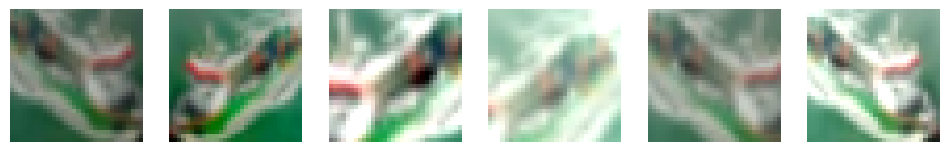

In [3]:
data = np.load(root/'assets/source_data/vision_errors.npz')
image = torch.tensor(data['images'][:1],dtype=torch.float32)/255
views = augment(image.repeat(6,1,1,1),contrastive=True)
mean = torch.tensor([.4914,.4822,.4465])[None,:,None,None]
std = torch.tensor([.247,.2435,.2616])[None,:,None,None]
display_images = (views*std+mean).clamp(0,1)
fig,axes = plt.subplots(1,6,figsize=(12,2))
for ax,v in zip(axes,display_images):
    ax.imshow(v.permute(1,2,0).numpy()); ax.axis('off')
plt.show()
assert ImageEncoder()(views).shape == (6,128)

In [4]:
rows = pd.DataFrame(evidence('vision')['rows'])
rows.groupby('model')[['accuracy','nll','set_coverage','set_size']].agg(['mean','std','count'])

accuracy                       nll                  \
                         mean       std count      mean       std count   
model                                                                     
contrastive_encoder  0.669400  0.000781     3  0.953016  0.007231     3   
imagenet_resnet18    0.837100  0.000557     3  0.467245  0.002648     3   
random_encoder       0.262733  0.001570     3  2.021715  0.002059     3   
supervised_full      0.927900       NaN     1  0.236948       NaN     1   
supervised_lowlabel  0.760000  0.004424     3  0.743312  0.010507     3   

                    set_coverage                  set_size                  
                            mean       std count      mean       std count  
model                                                                       
contrastive_encoder     0.883867  0.001629     3  2.127100  0.028858     3  
imagenet_resnet18       0.900033  0.000611     3  1.199200  0.008231     3  
random_encoder          0.903533  0.002843     3  6.595833  0.042155     3  
supervised_full         0.894900       NaN     1  0.933100       NaN     1  
supervised_lowlabel     0.902333  0.010889     3  1.690267  0.131114     3

## Full supervision and corruption
External ImageNet transfer has more information and a different architecture.
The full scratch reference has more CIFAR labels. Frozen random features isolate
the value of fitting the shared contrastive architecture.

In [5]:
rows[rows.model=='supervised_lowlabel'][['seed','accuracy','gaussian_noise_accuracy']]

,seed,accuracy,gaussian_noise_accuracy
3,0,0.7628,0.4412
7,1,0.7549,0.4181
11,2,0.7623,0.4008


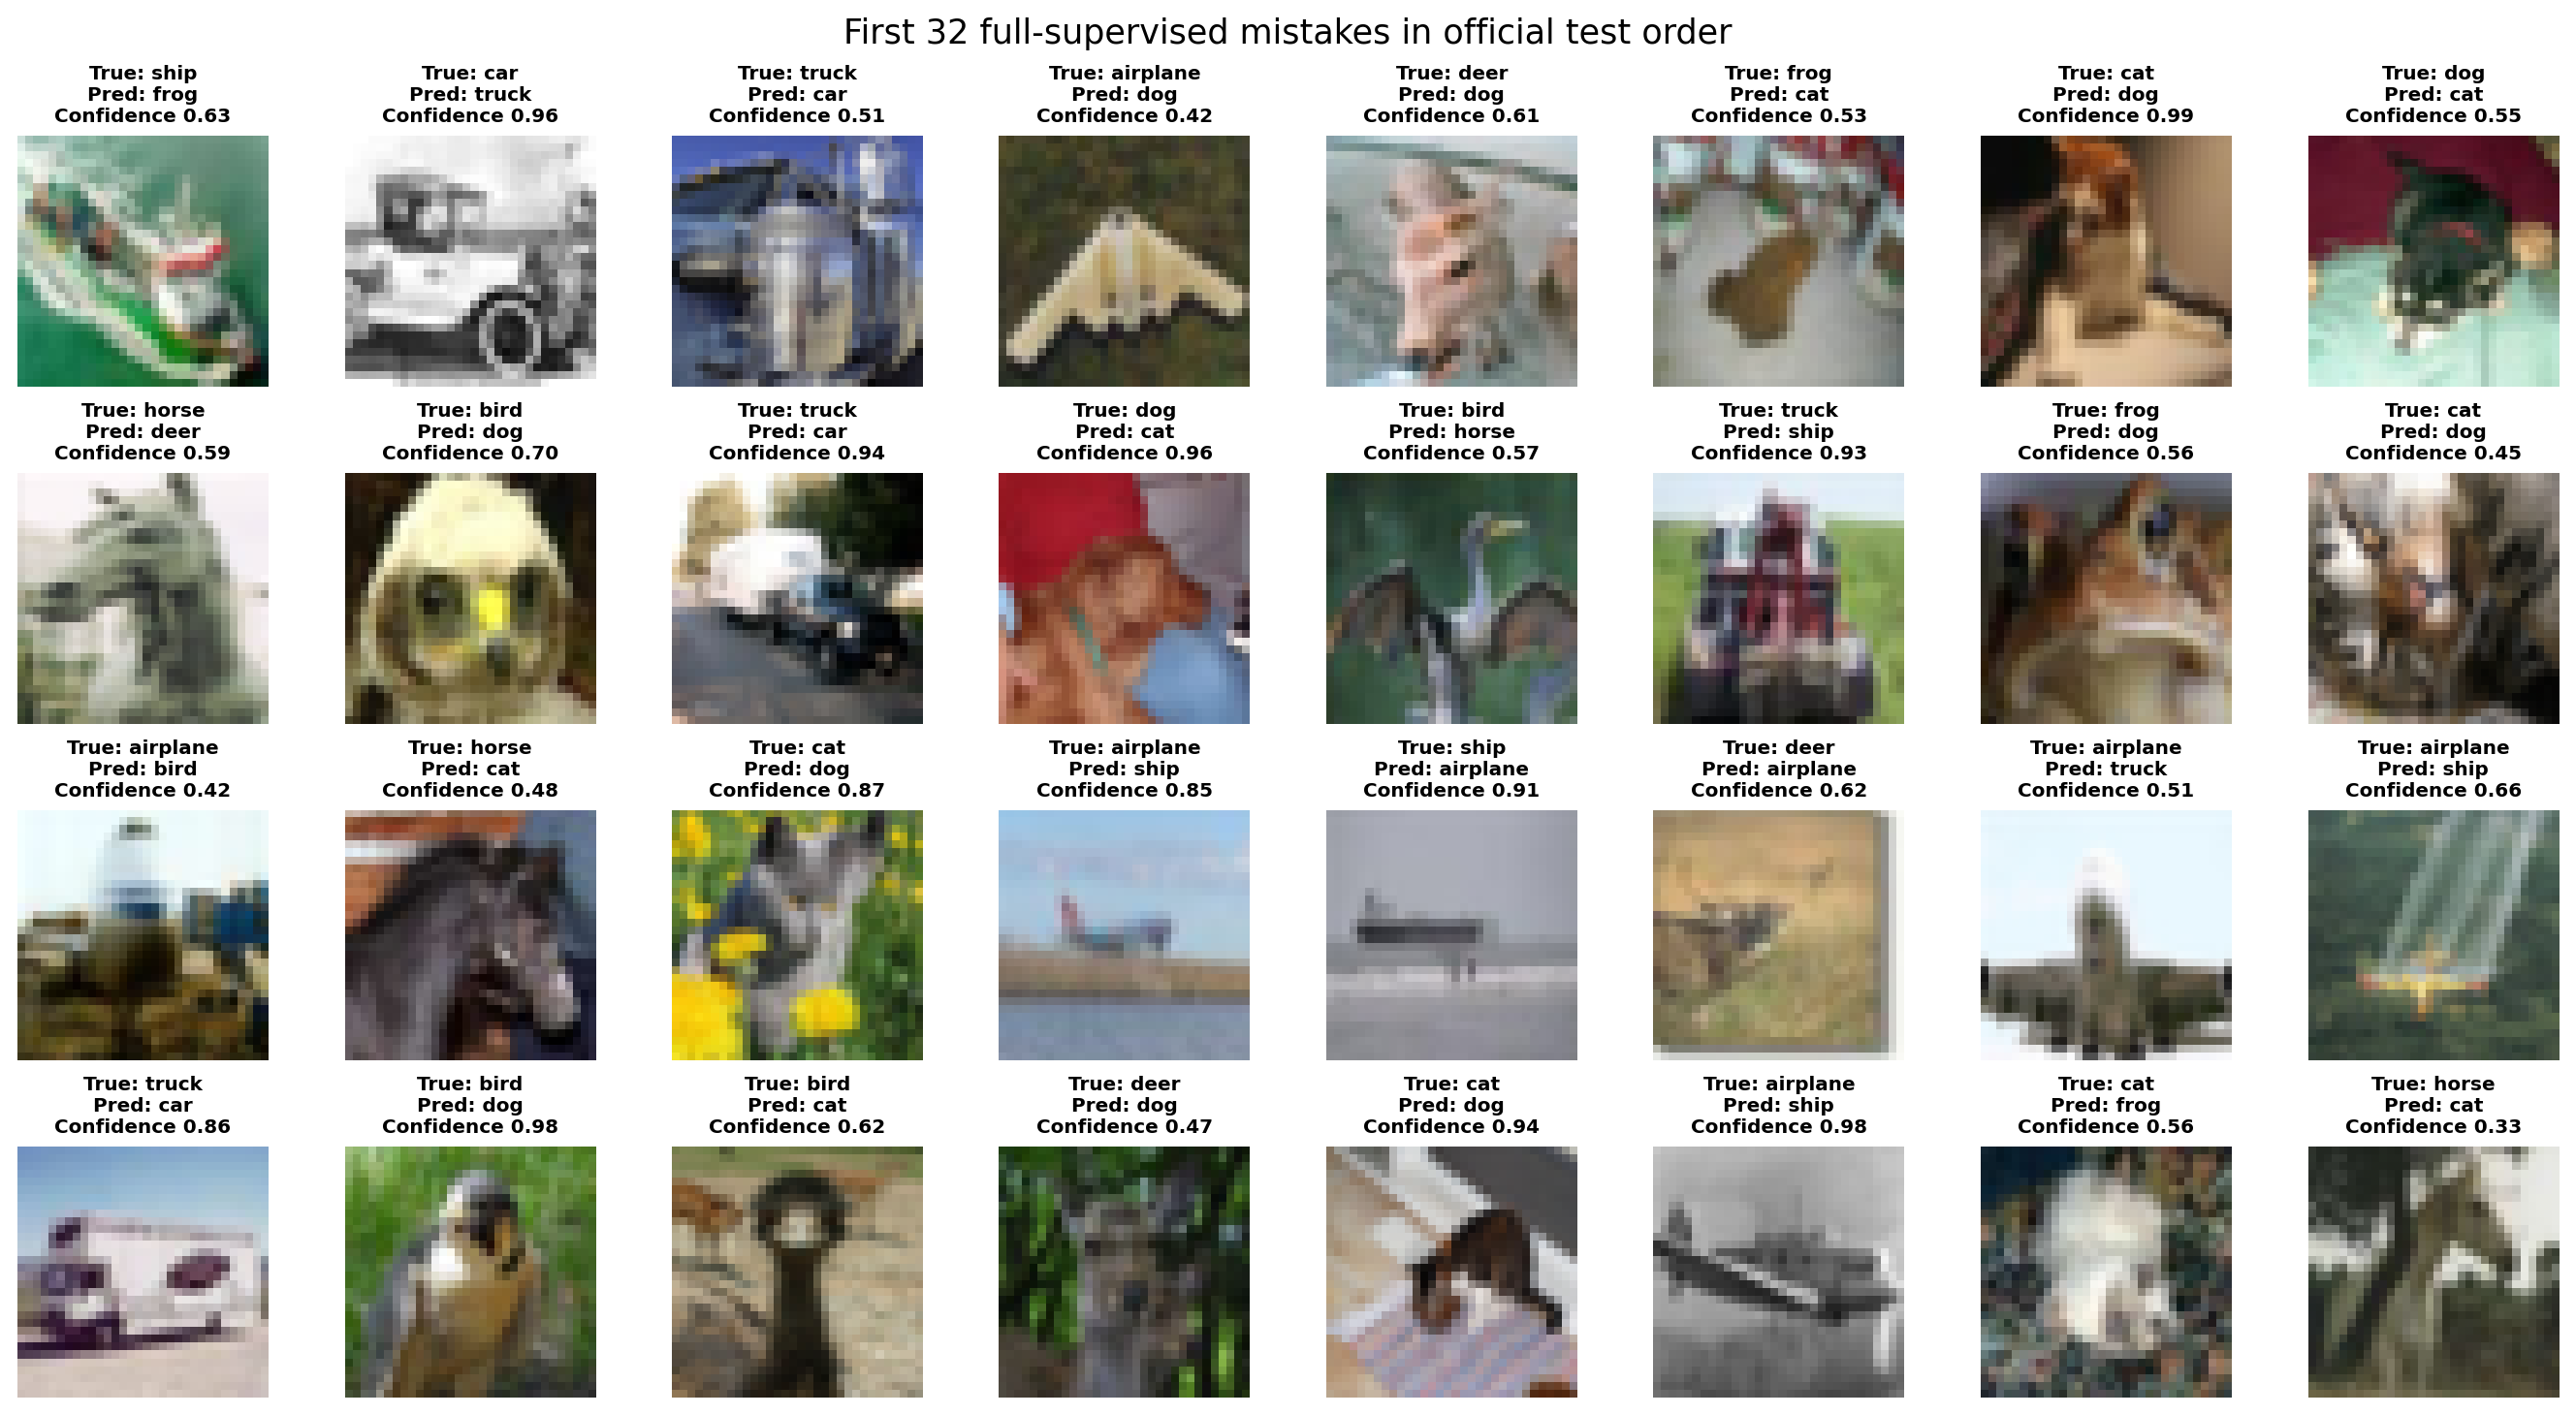

In [6]:
from IPython.display import Image, display
display(Image(filename=str(root/'assets/vision_errors.png')))

## Exercise and worked answer
What variation does the contrastive row's three-seed standard deviation measure?
It measures fitting-label subset variation in the downstream head; the encoder's
pretraining seed is fixed. It does not establish the variance of contrastive
pretraining. The error gallery follows official test order, so it does not hide
mistakes through visual selection.